## Parashikimi i shitjeve ditore

In [16]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, clean_data, add_columns
from src.forecasting import build_daily_series, validate_daily

sales, returns = clean_data(load_data())
sales = add_columns(sales)
returns = add_columns(returns)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Rreshta fillestare: 1,067,371
Dublikate:                                 hequr:    34335 | mbeten: 1,033,036
Anulime (ndahen te returns)                hequr:    19104 | mbeten: 1,013,932
Quantity <= 0                              hequr:     3393 | mbeten: 1,010,539
Price <= 0                                 hequr:     2626 | mbeten: 1,007,913
Kode te cilat nuk jane produkte            hequr:     4699 | mbeten: 1,003,214
Kodet e hequra (top 10):  {'POST': 1851, 'DOT': 1415, 'M': 846, 'C2': 267, 'ADJUST': 36, 'BANK CHARGES': 34, 'DCGS0058': 30, 'gift_0001_20': 26, 'gift_0001_30': 24, 'DCGSSGIRL': 23}
Rreshta te shitjes pas pastrimit: 1,003,214


In [3]:
last = sales["InvoiceDate"].max()
last_day = sales["Date"].max()
print("Fatura e fundit: ", last)
print("Te ardhurat e dites se fundit:", round(sales.loc[sales["Date"] == last_day, "Revenue"].sum()))
print("Mediana e te ardhurave ditore (ditet me shitje):", round(sales.groupby("Date")["Revenue"].sum().median()))

Fatura e fundit:  2011-12-09 12:50:00
Te ardhurat e dites se fundit: 198095
Mediana e te ardhurave ditore (ditet me shitje): 28180


In [4]:
daily = build_daily_series(sales, drop_last_day=False)
validate_daily(daily)
print(daily.shape)
daily.tail(10)

Kontrollet e serise ditore: OK
(739, 3)


,revenue,orders,is_open
Date,,,
2011-11-30,56088.10,107,True
2011-12-01,50601.86,121,True
2011-12-02,55917.17,120,True
2011-12-03,0.00,0,False
2011-12-04,24243.47,66,True
2011-12-05,80011.23,126,True
2011-12-06,55257.31,114,True
2011-12-07,72799.09,105,True
2011-12-08,77562.86,120,True


In [5]:
print(round(daily["revenue"].sum()), round(sales["Revenue"].sum()))

19642692 19642692


In [6]:
#ditet pa shitje
closed = daily[~daily["is_open"]]
print("Dite kalendarike:", len(daily))
print("Dite me shitje:", int(daily["is_open"].sum()))
print("Dite pa shitje:", len(closed))
print(closed.index.day_name().value_counts())

Dite kalendarike: 739
Dite me shitje: 604
Dite pa shitje: 135
Date
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64


In [7]:
run_id = daily["is_open"].ne(daily["is_open"].shift()).cumsum()
runs = (daily.reset_index().groupby(run_id.values).agg(
                nga=("Date", "min"),
                deri=("Date", "max"),
                dite=("Date", "size"),
                hapur=("is_open", "first")
            ))
runs[(~runs["hapur"]) & (runs["dite"] >= 3)]

,nga,deri,dite,hapur
6,2009-12-24,2010-01-03,11,False
32,2010-04-02,2010-04-05,4,False
114,2010-12-24,2011-01-03,11,False
146,2011-04-22,2011-04-25,4,False


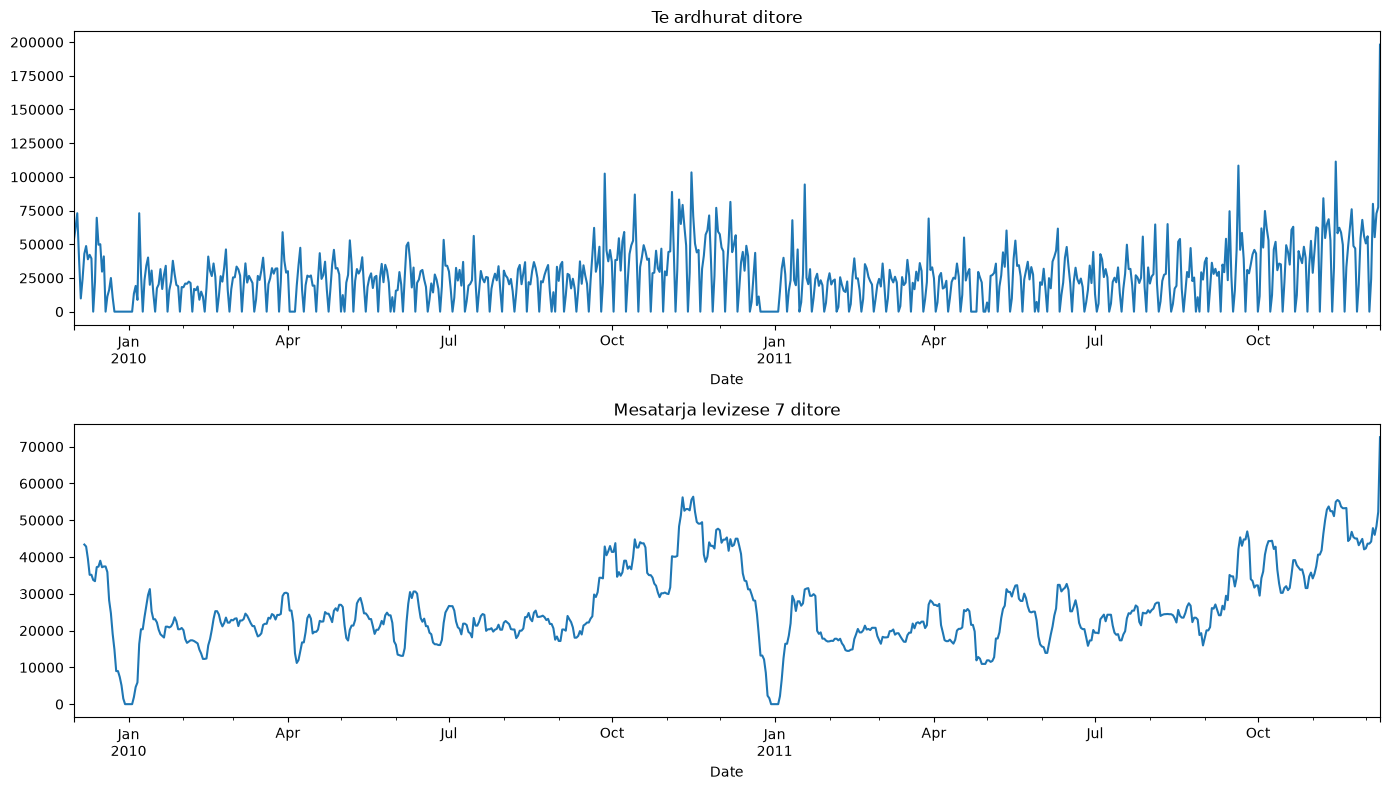

In [8]:
fig, axes = plt.subplots(2, 1 , figsize=(14, 8))
daily["revenue"].plot(ax=axes[0], title="Te ardhurat ditore")
daily["revenue"].rolling(7).mean().plot(ax=axes[1], title="Mesatarja levizese 7 ditore")
plt.tight_layout()
plt.show()

In [9]:
daily["weekday"] = daily.index.day_name()
order = ["Monday", "Tuesday",  "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(daily.groupby("weekday")["revenue"].agg(["mean", "median"]).reindex(order).round(0))

open_days = daily[daily["is_open"]]
print(open_days["revenue"].describe().round(0))
open_days["revenue"].nlargest(5)

              mean   median
weekday                    
Monday     32535.0  27747.0
Tuesday    36603.0  30267.0
Wednesday  31841.0  28762.0
Thursday   37830.0  33788.0
Friday     29872.0  25969.0
Saturday      93.0      0.0
Sunday     17002.0  16868.0
count       604.0
mean      32521.0
std       18206.0
min        3440.0
25%       21278.0
50%       28180.0
75%       39972.0
max      198095.0
Name: revenue, dtype: float64


Date
2011-12-09    198094.64
2011-11-14    111348.61
2011-09-20    108364.34
2010-11-15    103336.35
2010-09-27    102425.05
Name: revenue, dtype: float64

In [12]:
inv = sales.groupby(["Date", "Invoice"])["Revenue"].sum().reset_index()
open_days = daily[daily["is_open"]]

for d in open_days["revenue"].nlargest(6).index:
    day = inv[inv["Date"] == d].sort_values("Revenue", ascending=False)
    top = day.iloc[0]
    share = top["Revenue"] / day["Revenue"].sum() * 100
    print(d.date(), "| dita:", round(day["Revenue"].sum()), "| fatura me e madhe:", top["Invoice"], round(top["Revenue"]), f"({share:.0f}%)")

2011-12-09 | dita: 198095 | fatura me e madhe: 581483 168470 (85%)
2011-11-14 | dita: 111349 | fatura me e madhe: 576365 50654 (45%)
2011-09-20 | dita: 108364 | fatura me e madhe: 567423 31698 (29%)
2010-11-15 | dita: 103336 | fatura me e madhe: 533027 49845 (48%)
2010-09-27 | dita: 102425 | fatura me e madhe: 524181 33168 (32%)
2011-01-18 | dita: 94365 | fatura me e madhe: 541431 77184 (82%)


In [17]:
row = sales[sales["Date"] == "2011-12-09"].nlargest(1, "Revenue").iloc[0]
print(row[["Invoice", "InvoiceDate", "StockCode", "Description", "Quantity", "Price", "Customer ID", "Revenue"]])

returns[(returns["StockCode"] == row["StockCode"]) & (returns["Customer ID"] == row["Customer ID"])][["Invoice", "InvoiceDate", "Quantity", "Revenue"]]

Invoice                             581483
InvoiceDate            2011-12-09 09:15:00
StockCode                            23843
Description    PAPER CRAFT , LITTLE BIRDIE
Quantity                             80995
Price                                 2.08
Customer ID                          16446
Revenue                           168469.6
Name: 1001747, dtype: object


,Invoice,InvoiceDate,Quantity,Revenue
1065883,C581484,2011-12-09 09:27:00,-80995,-168469.6


In [18]:
print("Shitje:", round(sales["Revenue"].sum()), "| Anulime:", round(returns["Revenue"].sum()))
print("Anulimet si % e shitjeve:", round(-returns["Revenue"].sum() / sales["Revenue"].sum() * 100, 1))

Shitje: 19642692 | Anulime: -1462051
Anulimet si % e shitjeve: 7.4
